## Gradient Descent

In [11]:
from sklearn.datasets import make_regression
import numpy as np

In [12]:
X,y = make_regression(n_samples=4, n_features=1, n_informative=1, n_targets=1, noise=80, random_state=13)

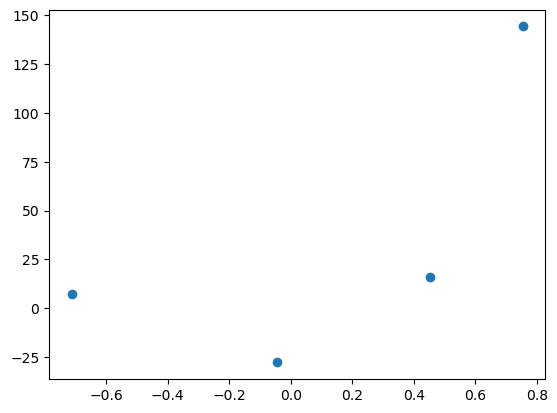

In [13]:
import matplotlib.pyplot as plt
plt.scatter(X,y)

In [14]:
#apply OLS
from sklearn.linear_model import LinearRegression

In [15]:
reg = LinearRegression()
reg.fit(X,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [16]:
reg.coef_

array([78.35063668])

In [17]:
reg.intercept_

np.float64(26.15963284313262)

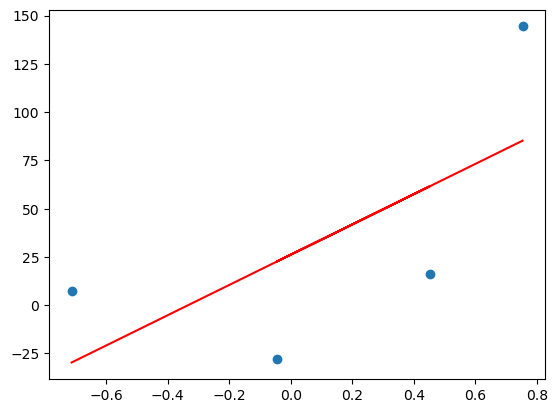

In [18]:
plt.scatter(X,y)
plt.plot(X, reg.predict(X), color='red')

In [19]:
#lets apply gradient descent assuming slope is constant m=78.35
# and lets assume the starting value for intercept b = 0
y_pred = ((78.35 * X) + 0).reshape(4)

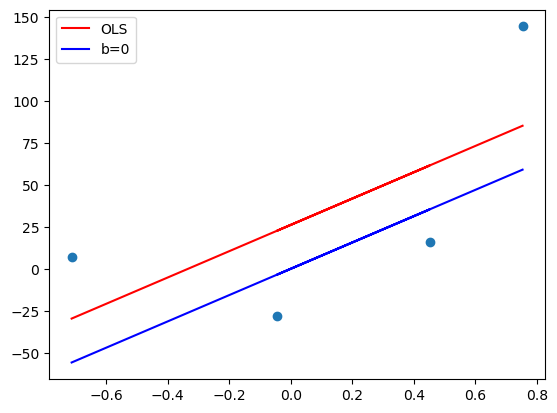

In [20]:
plt.scatter(X,y)
plt.plot(X, reg.predict(X),color='red',label='OLS')
plt.plot(X,y_pred,color='blue',label='b=0')
plt.legend()
plt.show()

In [21]:
m = 78.35
b = 0

In [22]:
loss_slope = -2 * np.sum(y - m*X.ravel() - b)
loss_slope

np.float64(-209.27763408209216)

In [23]:
#lets take learning rate = 0.1
lr = 0.1

step_size = loss_slope*0.1
step_size

np.float64(-20.927763408209216)

In [24]:
b = b - step_size
b

np.float64(20.927763408209216)

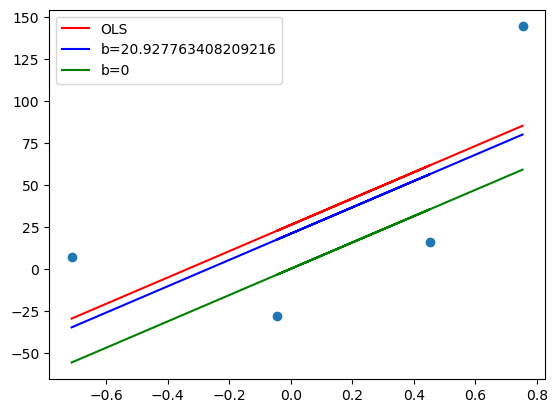

In [25]:
y_pred1 = ((78.35 * X) + b).reshape(4)

plt.scatter(X,y)
plt.plot(X, reg.predict(X), color='red', label="OLS")
plt.plot(X, y_pred1, color='blue', label='b={}'.format(b))
plt.plot(X, y_pred, color='green',label='b=0')
plt.legend()
plt.show()

In [26]:
# iteration 2
loss_slope = -2 * np.sum(y - m*X.ravel() - b)
loss_slope

np.float64(-41.85552681641843)

In [27]:
step_size = loss_slope*lr
step_size

np.float64(-4.185552681641844)

In [28]:
b = b - step_size
b

np.float64(25.11331608985106)

In [29]:
y_pred2 = ((78.35 * X) + b).reshape(4)

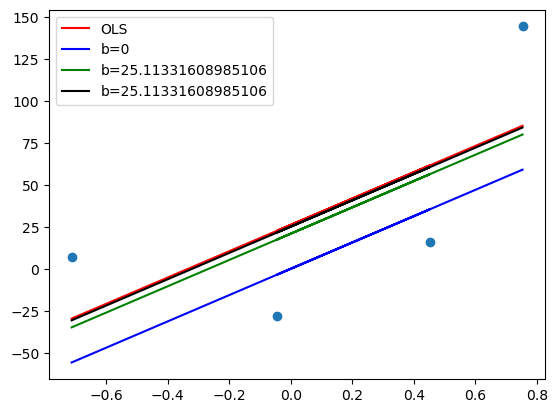

In [30]:
plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label="OLS")
plt.plot(X,y_pred,color='blue',label='b=0')
plt.plot(X,y_pred1,color='green',label='b={}'.format(b))
plt.plot(X,y_pred2,color='black',label='b={}'.format(b))
plt.legend()
plt.show()



In [31]:
#iteration 3
loss_slope = -2 * np.sum(y - m*X.ravel() - b)
loss_slope

np.float64(-8.371105363283675)

In [32]:
step_size = loss_slope*lr
step_size

np.float64(-0.8371105363283675)

In [33]:
b = b - step_size
b

np.float64(25.95042662617943)

In [34]:
y_pred3 = ((78.35 * X) + b).reshape(4)

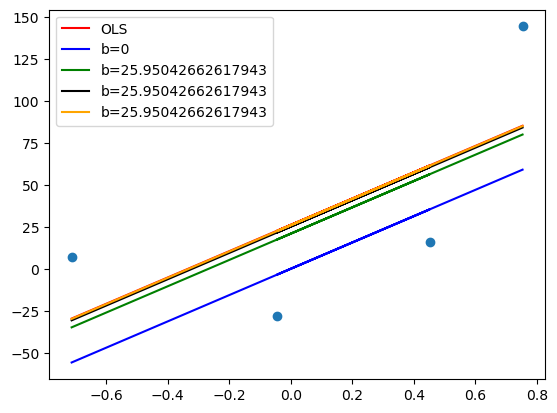

In [35]:
plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label="OLS")
plt.plot(X,y_pred,color='blue',label='b=0')
plt.plot(X,y_pred1,color='green',label='b={}'.format(b))
plt.plot(X,y_pred2,color='black',label='b={}'.format(b))    
plt.plot(X,y_pred3,color='orange',label='b={}'.format(b))
plt.legend()
plt.show()

In [36]:
#iteration 4
loss_slope = -2 * np.sum(y - m*X.ravel() - b)
loss_slope

np.float64(-1.674221072656735)

In [37]:
step_size = loss_slope*lr
step_size

np.float64(-0.16742210726567353)

In [38]:
b = b - step_size
b

np.float64(26.1178487334451)

In [39]:
y_pred4= ((78.35 * X) + b).reshape(4)


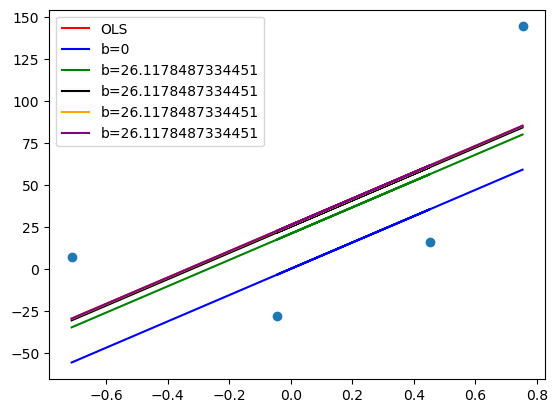

In [40]:
plt.scatter(X,y)
plt.plot(X,reg.predict(X),color='red',label="OLS")
plt.plot(X,y_pred,color='blue',label='b=0')
plt.plot(X,y_pred1,color='green',label='b={}'.format(b))
plt.plot(X,y_pred2,color='black',label='b={}'.format(b))
plt.plot(X,y_pred3,color='orange',label='b={}'.format(b))
plt.plot(X,y_pred4,color='purple',label='b={}'.format(b))
plt.legend()
plt.show()

### Scratch

In [41]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np

In [42]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1, noise=20,random_state=13)

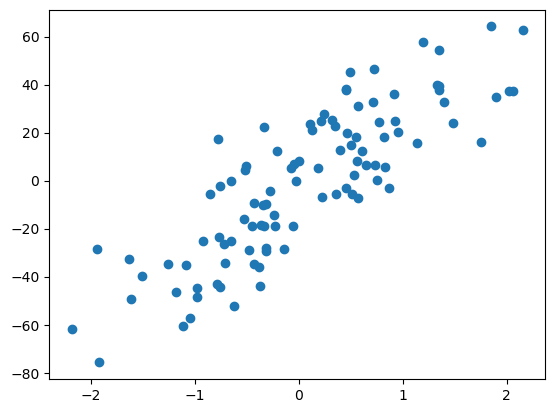

In [43]:
plt.scatter(X,y)

In [44]:
from sklearn.linear_model import LinearRegression


In [45]:
lr = LinearRegression()

In [46]:
lr.fit(X,y)
print(lr.coef_)
print(lr.intercept_)

[27.82809103]
-2.29474455867698


In [47]:
class GDRegressor:

    def __init__(self, learning_rate, epochs):
        self.m = 100
        self.b = -120
        self.lr = learning_rate
        self.epochs = epochs


    def fit(self,X,y):
        #calculate the b using GD
        for i in range(self.epochs):
            loss_slope_b = -2 * np.sum(y - self.m*X.ravel() - self.b)
            loss_slope_m = -2 * np.sum((y - self.m*X.ravel() - self.b)*X.ravel())

            self.b = self.b - (self.lr * loss_slope_b)
            self.m = self.m - (self.lr * loss_slope_m)
        print(self.b, self.m)

    def predict(self, X):
        return self.m*X + self.b


In [48]:
gd = GDRegressor(0.001, 40)

In [49]:
gd.fit(X,y)

-2.3261748004792975 27.884679678160477


In [50]:
gd.predict(X)

array([[-22.19096022],
       [-14.51584138],
       [-14.9789146 ],
       [ 24.24320158],
       [  4.30641483],
       [ 21.6884285 ],
       [ -9.11124939],
       [  2.83098378],
       [-22.43101974],
       [-14.31371722],
       [ 53.86761239],
       [  8.75077234],
       [  3.46826312],
       [ -8.80729579],
       [-23.75909307],
       [ 10.31000797],
       [ 15.51678483],
       [  7.69926809],
       [-47.362943  ],
       [ 46.4508722 ],
       [-24.32688103],
       [-16.60215746],
       [-28.21250521],
       [ 57.63656543],
       [ -8.10805472],
       [-48.03176953],
       [-11.76843635],
       [-11.30848979],
       [-15.74906254],
       [-16.91444135],
       [ 17.80558956],
       [ 19.03100947],
       [ 10.31899875],
       [-37.50565247],
       [-63.31318361],
       [-35.38119858],
       [  3.73739507],
       [ 34.76928649],
       [-32.64188521],
       [ 13.35231277],
       [-44.51137624],
       [ -2.39279201],
       [-10.0818667 ],
       [ 10

In [51]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split

In [52]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1, noise=20, random_state=13)

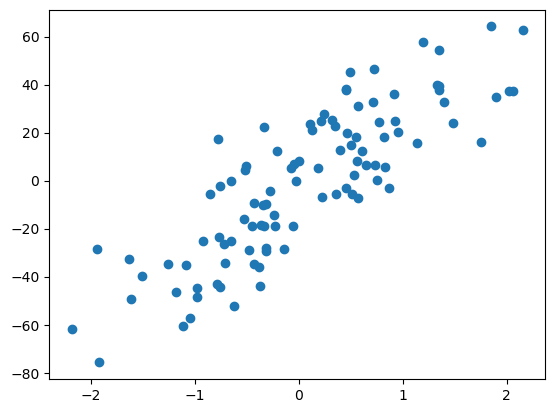

In [53]:
plt.scatter(X,y)

In [54]:
from sklearn.linear_model import LinearRegression

In [55]:
lr = LinearRegression()

In [56]:
lr.fit(X,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [57]:
print(lr.coef_)
print(lr.intercept_)

[27.82809103]
-2.29474455867698


In [58]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(lr, X, y, cv=10)
np.mean(scores)

np.float64(0.6375011587464419)

In [59]:
gd1 = GDRegressor(0.001, 40)

In [60]:
gd.fit(X,y)

-2.2947589592259776 27.828125604345274


In [61]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=2)

In [63]:
lr = LinearRegression()

In [64]:
lr.fit(X_train, y_train)
print(lr.coef_)
print(lr.intercept_)

[28.12597332]
-2.2710144261783825


In [68]:
y_pred = lr.predict(X_test)
from sklearn.metrics import r2_score 
r2_score(y_test, y_pred)

0.6345158782661012

In [69]:
gd.fit(X_train, y_train)

-2.2709045828402528 28.125545880025513


In [70]:
y_pred = lr.predict(X_test)
from sklearn.metrics import r2_score 
r2_score(y_test, y_pred)

0.6345158782661012